# Reproducing the results in *Lab-Accurate, Field-Blind*

This notebook rebuilds every table and every derived number in the paper from
the saved result files in `../results/`, and displays the figures in
`../figures/`. It runs in a few seconds and needs nothing but `numpy` and
`pandas`.

It does **not** retrain anything. Training, quantization and the Grad-CAM
sweeps are what the numbered scripts in `../scripts/` do; the JSON files this
notebook reads are their output. The split is deliberate: checking the
paper's arithmetic should not cost a day of CPU.

To regenerate the artefacts themselves from scratch, see the pipeline order in
the repository README.

In [1]:
import json, csv, random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

RESULTS = Path("../results")
FIGURES = Path("../figures")

def load(name):
    with open(RESULTS / name) as f:
        return json.load(f)

pd.set_option("display.width", 100)
pd.set_option("display.max_colwidth", 60)
print("result files:", len(list(RESULTS.glob('*.json'))))

result files: 36


## Table 6 — the gap itself

Top-1 accuracy on the laboratory test split and on the held-out field set, at
both precisions.

In [2]:
rows = []
for label, fp32, q in [
    ("Tomato (8 classes)",      "results_tomato_fp32.json",     "results_tomato_quantized.json"),
    ("Multi-crop (21 classes)", "results_multicrop_fp32.json",  "results_multicrop_quantized.json"),
]:
    a, b = load(fp32), load(q)
    rows.append([label, "32-bit", 100*a["pv_test"]["accuracy"],
                 100*a["pd_field"]["accuracy"]])
    rows.append([label, "8-bit",  100*b["int8"]["pv_test_accuracy"],
                 100*b["int8"]["pd_field_accuracy"]])

t6 = pd.DataFrame(rows, columns=["Model", "Precision", "Laboratory %", "Field %"])
t6.round(2)

,Model,Precision,Laboratory %,Field %
0,Tomato (8 classes),32-bit,78.75,12.10
1,Tomato (8 classes),8-bit,79.48,11.69
2,Multi-crop (21 classes),32-bit,86.84,9.15
3,Multi-crop (21 classes),8-bit,86.62,9.10


### The two chance floors

The paper compares field accuracy against a uniform-guessing rate *and*
against a constant predictor that always answers the most frequent class.
Both are computed here from the manifest rather than quoted.

In [3]:
manifest = list(csv.DictReader(open(RESULTS / "manifest.csv")))

def floors(rows, name):
    c = Counter(r["class_name"] for r in rows)
    n = sum(c.values())
    top, k = c.most_common(1)[0]
    return {
        "set": name, "n": n, "classes": len(c),
        "uniform %": round(100 / len(c), 2),
        "majority %": round(100 * k / n, 2),
        "majority class": top.split("___")[-1],
    }

pd.DataFrame([
    floors([r for r in manifest if r["is_tomato"] == "True" and r["domain"] == "pd_field"],
           "tomato field (744)"),
    floors([r for r in manifest if r["domain"] == "pd_field"], "multi-crop field (2010)"),
])

,set,n,classes,uniform %,majority %,majority class
0,tomato field (744),744,8,12.50,20.30,Septoria_leaf_spot
1,multi-crop field (2010),2010,21,4.76,9.55,Northern_Leaf_Blight


In [4]:
# D_ft-test is rebuilt with the same seed the fine-tuning scripts use, so the
# majority rate quoted for the common basis is reproduced rather than asserted.
field = [r for r in manifest if r["is_tomato"] == "True" and r["domain"] == "pd_field"]
by = {}
for r in field:
    by.setdefault(r["class_name"], []).append(r)
random.seed(123)
ft_test = []
for k in sorted(by):
    rs = by[k][:]
    random.shuffle(rs)
    ft_test += rs[20:]

c = Counter(r["class_name"] for r in ft_test)
top, k = c.most_common(1)[0]
print(f"D_ft-test: n={len(ft_test)}  uniform={100/len(c):.2f}%  "
      f"majority={100*k/len(ft_test):.2f}% ({top.split('___')[-1]})")

D_ft-test: n=584  uniform=12.50%  majority=22.43% (Septoria_leaf_spot)


### Bootstrap intervals on the gap

In [5]:
b = load("bootstrap_ci_results.json")
pd.DataFrame([{
    "experiment": k,
    "lab %": round(100*v["lab_acc"], 2),
    "field %": round(100*v["field_acc"], 2),
    "gap pp": round(100*v["gap"], 1),
    "gap 95% CI": f"{100*v['gap_ci'][0]:.1f} – {100*v['gap_ci'][1]:.1f}",
    "excludes zero": v["gap_ci_excludes_zero"],
} for k, v in b.items()])

,experiment,lab %,field %,gap pp,gap 95% CI,excludes zero
0,tomato,79.48,11.69,67.8,64.0 – 71.5,True
1,multicrop,86.62,9.10,77.5,75.5 – 79.5,True


## Table 7 — size and latency

Compression is close to free for this architecture, which is what makes the
gap in Table 6 a domain problem rather than a compression problem.

In [6]:
rows = []
for label, key in [("Tomato", "tomato"), ("Multi-crop", "multicrop")]:
    q = load(f"results_{key}_quantized.json")
    rows.append([
        label,
        round(q["fp32_tflite_size_mb"], 2), round(q["int8_tflite_size_mb"], 2),
        f"{q['size_reduction_x']:.2f}x",
        round(q["fp32_tflite"]["latency_pv_test"]["mean_ms"], 2),
        round(q["int8"]["latency_pv_test"]["mean_ms"], 2),
    ])
pd.DataFrame(rows, columns=["Model", "32-bit MB", "8-bit MB", "Reduction",
                            "32-bit ms", "8-bit ms"])

,Model,32-bit MB,8-bit MB,Reduction,32-bit ms,8-bit ms
0,Tomato,5.46,1.77,3.09x,1.49,0.88
1,Multi-crop,5.53,1.78,3.10x,1.59,1.04


## Table 8 and Figure 5 — the collapse is uneven

Per-class accuracy for the deployed 8-bit tomato model. The ordering inverts
between the two domains.

In [7]:
pc = load("perclass_tomato.json")
rows = []
for cls, lab in pc["lab"].items():
    fld = pc["field"][cls]
    rows.append([cls.split("___")[-1].replace("_", " "),
                 f"{100*lab[0]:.1f}% ({lab[1]}/{lab[2]})",
                 f"{100*fld[0]:.1f}% ({fld[1]}/{fld[2]})",
                 100*fld[0]])
t8 = (pd.DataFrame(rows, columns=["Class", "Laboratory", "Field", "_sort"])
        .sort_values("_sort", ascending=False).drop(columns="_sort")
        .reset_index(drop=True))
t8

,Class,Laboratory,Field
0,Early blight,67.8% (61/90),38.6% (34/88)
1,healthy,95.6% (86/90),31.7% (20/63)
2,Tomato Yellow Leaf Curl Virus,88.9% (80/90),14.5% (11/76)
3,Late blight,68.9% (62/90),9.0% (10/111)
4,Septoria leaf spot,62.2% (56/90),4.6% (7/151)
5,Leaf Mold,77.8% (70/90),3.3% (3/91)
6,Bacterial spot,88.9% (80/90),1.8% (2/110)
7,Tomato mosaic virus,89.5% (51/57),0.0% (0/54)


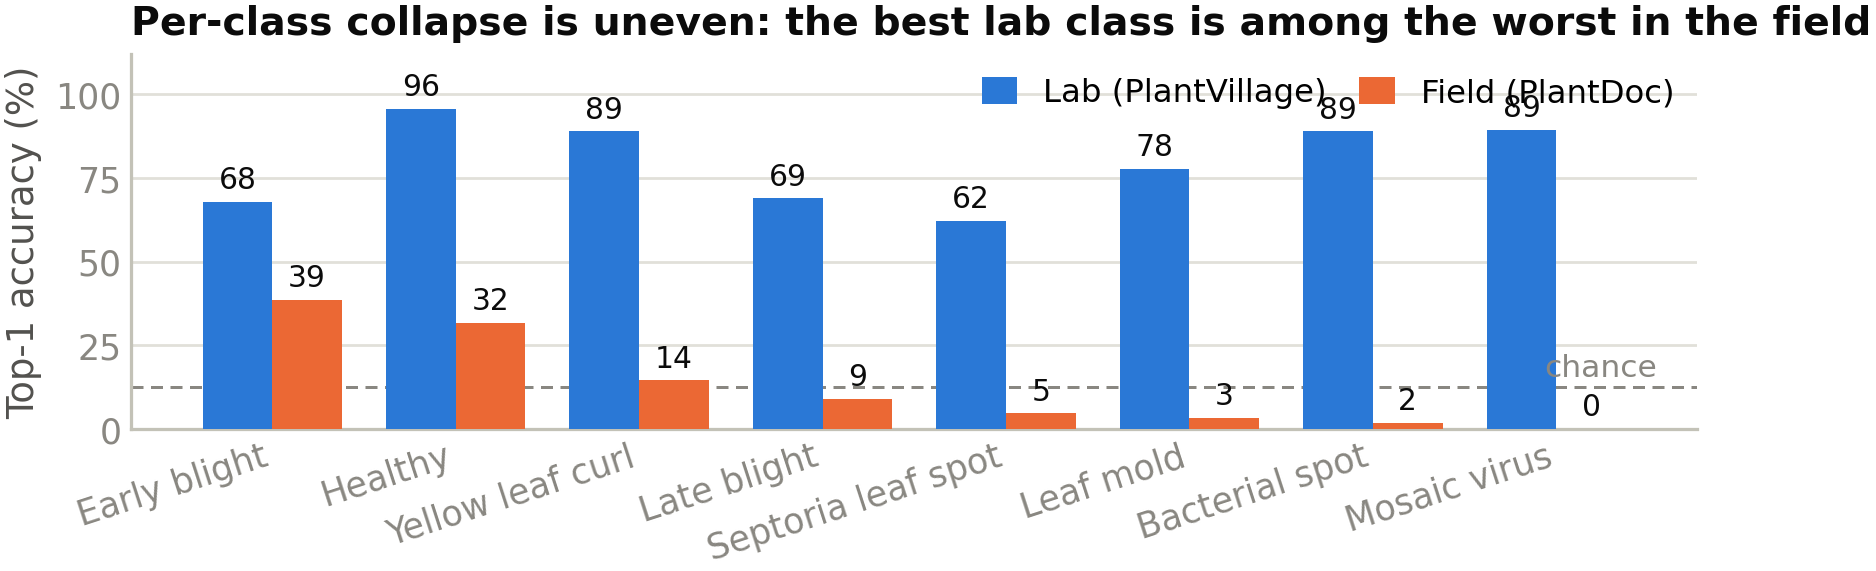

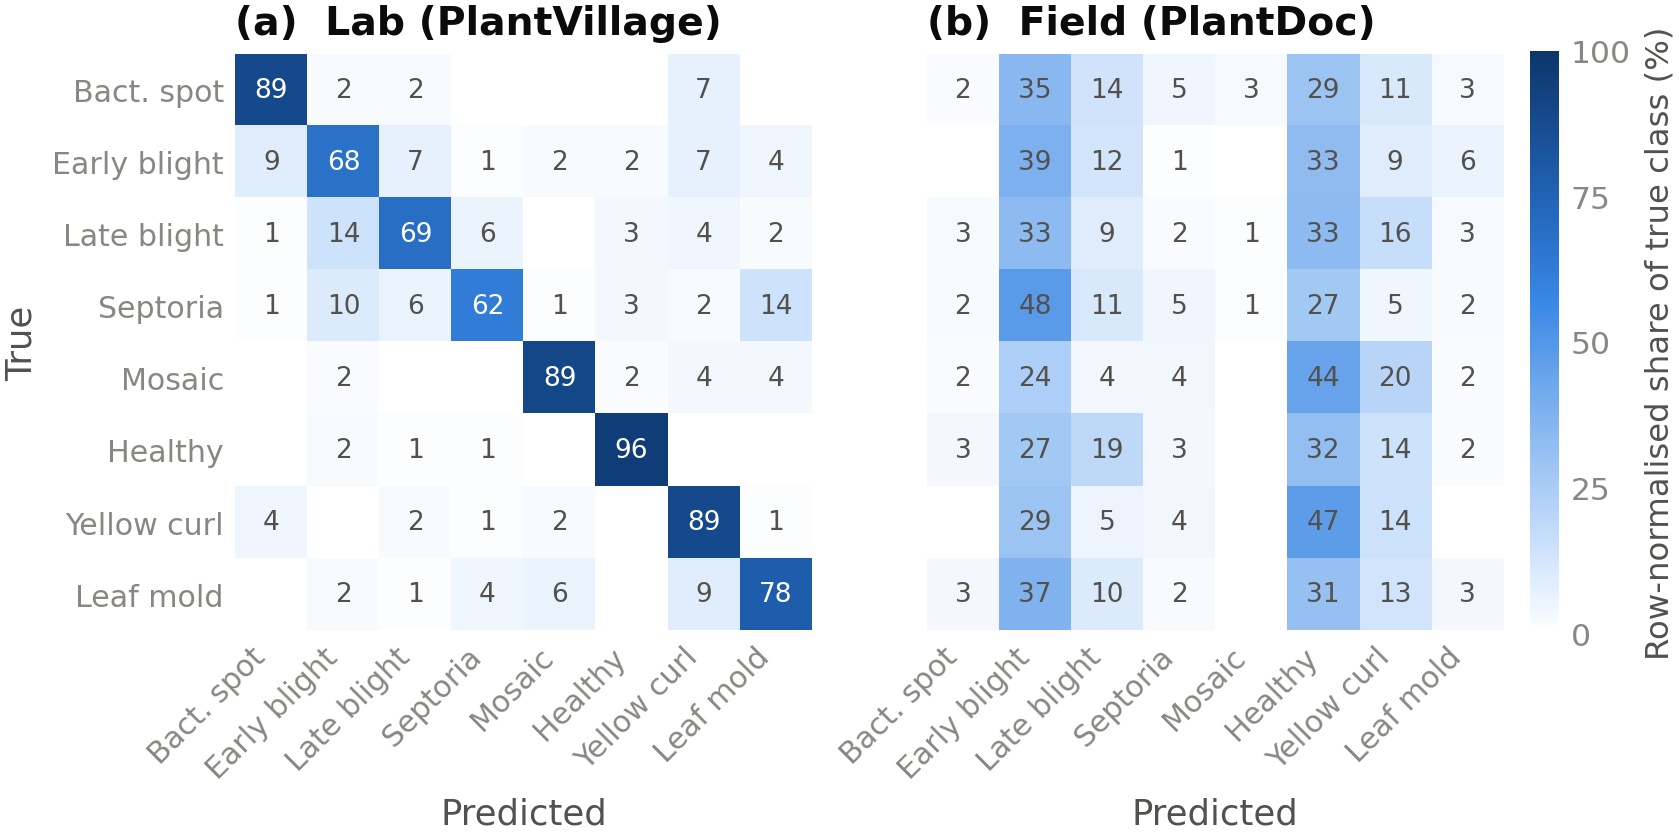

In [8]:
from IPython.display import Image, display
display(Image(filename=str(FIGURES / "perclass_v2.png"), width=760))
display(Image(filename=str(FIGURES / "confmat_v2.png"), width=760))

## Section 5.4 and Figure 9 — where the model is actually looking

Grad-CAM attention landing inside the annotated leaf box, $E(x)$, against the
chance level set by that box's own area, $C(x)$. Every arm is scored on the
495 box-annotated images inside $D_{\text{ft-test}}$, the same basis the
accuracy table uses, so no adapted arm is scored on its own training images.

In [9]:
ft = load("gradcam_fttest_results.json")["variants"]
rows = []
for arm, v in ft.items():
    for grp in ("all", "correct", "misclassified"):
        g = v[grp]
        rows.append([arm, grp, g["n"], round(g["mean_energy_in_box"], 4),
                     round(g["mean_chance"], 4), round(g["mean_excess"], 4),
                     f"[{g['excess_ci95'][0]:+.4f}, {g['excess_ci95'][1]:+.4f}]",
                     "yes" if (g["excess_ci95"][0] > 0) or (g["excess_ci95"][1] < 0) else "no"])
att = pd.DataFrame(rows, columns=["arm", "subset", "n", "E(x)", "C(x)",
                                  "excess", "95% CI", "CI excludes 0"])
att

,arm,subset,n,E(x),C(x),excess,95% CI,CI excludes 0
0,baseline,all,495,0.5132,0.4999,0.0133,"[+0.0025, +0.0240]",yes
1,baseline,correct,60,0.4659,0.4469,0.0190,"[-0.0133, +0.0498]",no
2,baseline,misclassified,435,0.5197,0.5072,0.0125,"[+0.0010, +0.0237]",yes
3,cutmix,all,495,0.4852,0.4999,-0.0147,"[-0.0251, -0.0049]",yes
4,cutmix,correct,75,0.5116,0.4879,0.0237,"[-0.0048, +0.0520]",no
5,cutmix,misclassified,420,0.4804,0.5020,-0.0216,"[-0.0325, -0.0112]",yes
6,pretrained,all,495,0.4954,0.4999,-0.0045,"[-0.0165, +0.0076]",no
7,pretrained,correct,107,0.5866,0.5413,0.0453,"[+0.0171, +0.0740]",yes
8,pretrained,misclassified,388,0.4702,0.4885,-0.0182,"[-0.0309, -0.0052]",yes
9,stacked,all,495,0.5025,0.4999,0.0026,"[-0.0076, +0.0126]",no


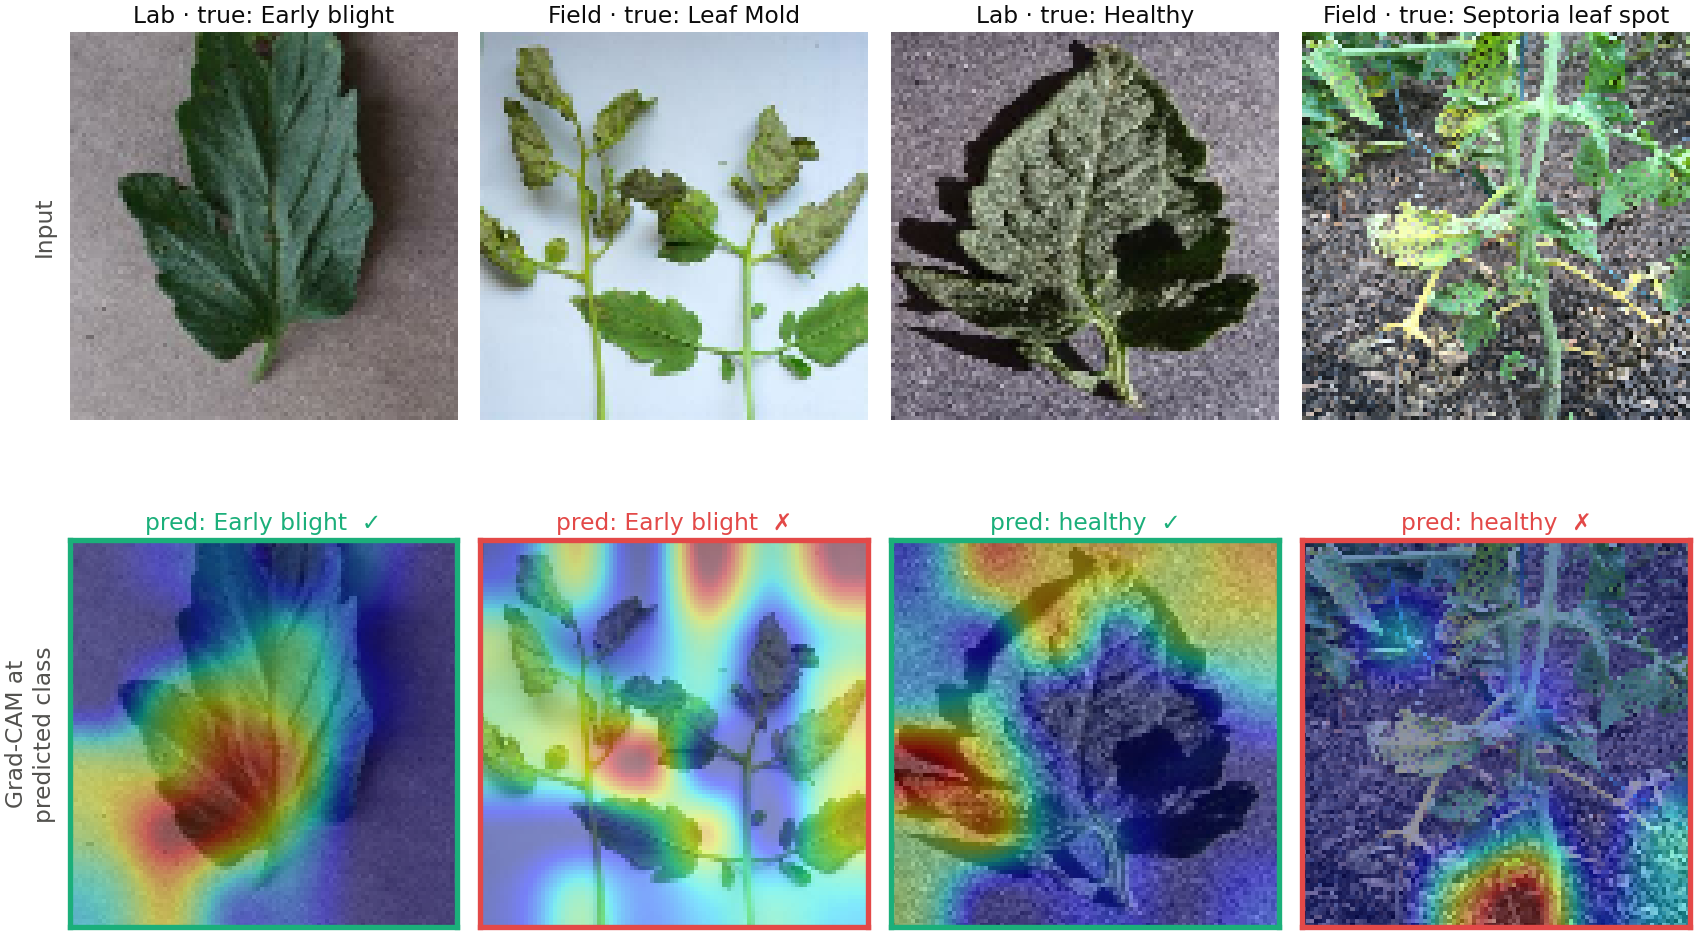

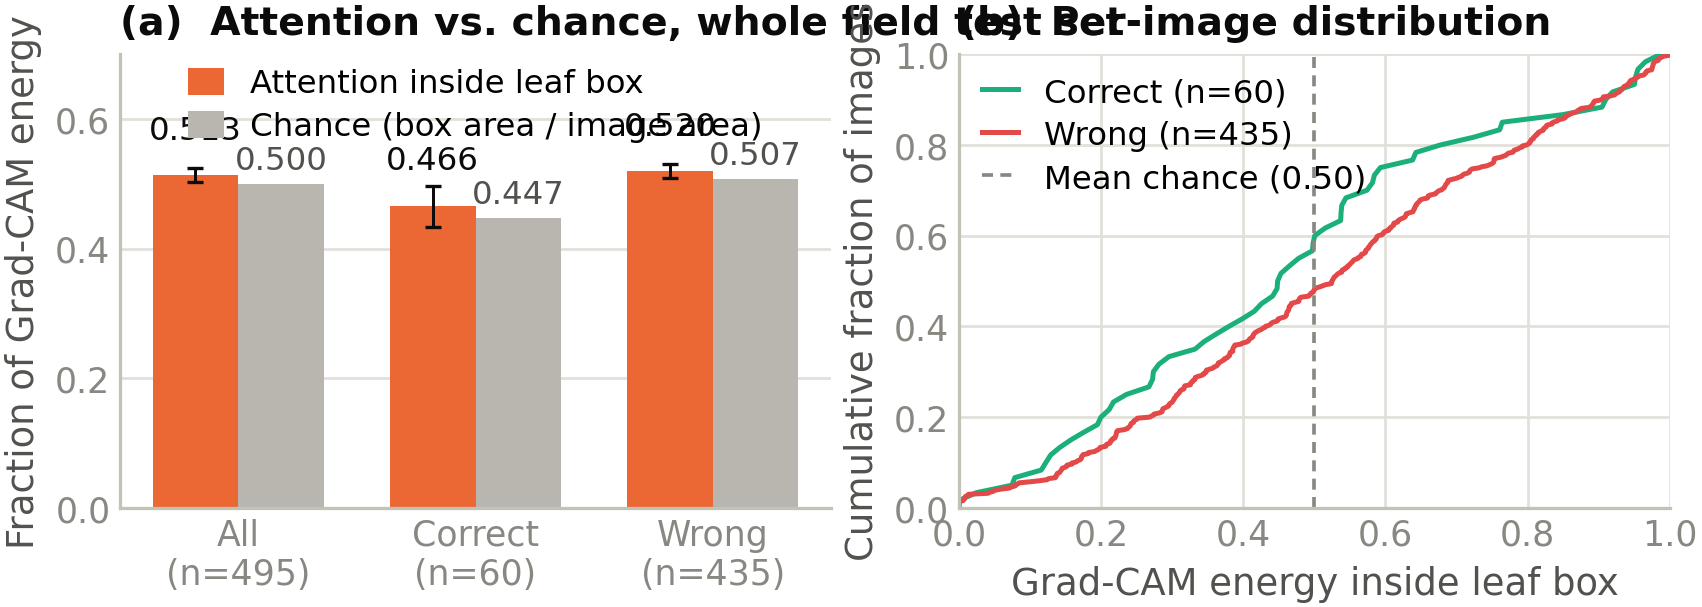

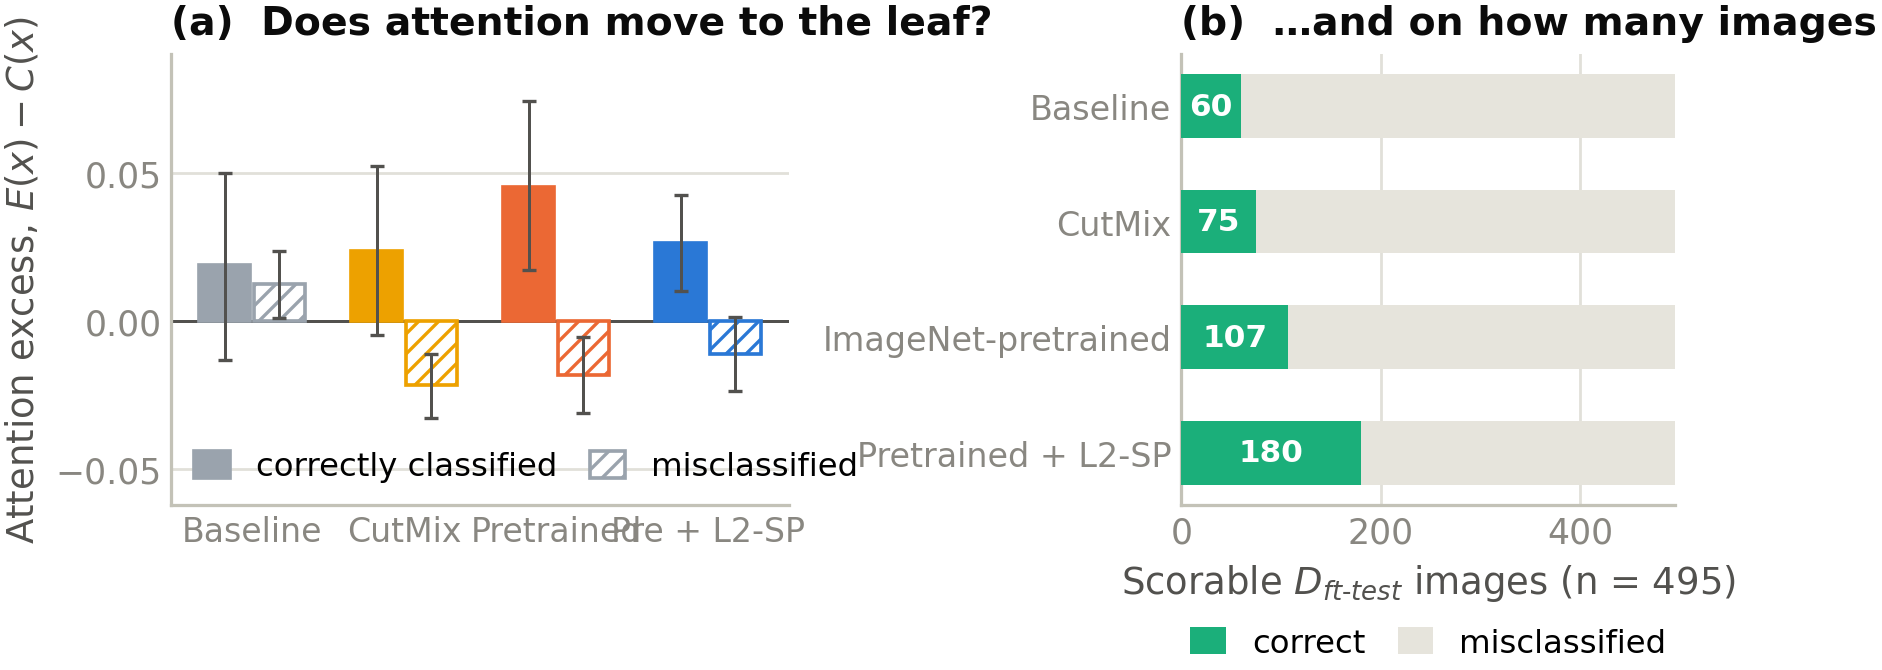

In [10]:
display(Image(filename=str(FIGURES / "gradcam_field_v3.png"), width=760))
display(Image(filename=str(FIGURES / "gradcam_bbox_energy_v3.png"), width=760))
display(Image(filename=str(FIGURES / "attention_comparison.png"), width=760))

### The null result the paper reports

Figure 7 invites the reading that the model learned a photographic setup: the
images it gets right look like close-ups. The paper tests that against the one
number available for it, the leaf's fractional area $C(x)$, and reports that
it does not hold.

In [11]:
per = load("gradcam_bbox_energy_results.json")["per_image"]
held = {r["path"].split("/")[-1] for r in ft_test}
kept = [p for p in per if p["file"] in held]

cc = np.array([p["chance"] for p in kept if p["correct"]])
cw = np.array([p["chance"] for p in kept if not p["correct"]])
rng = np.random.default_rng(0)
boot = np.array([rng.choice(cc, cc.size, True).mean() - rng.choice(cw, cw.size, True).mean()
                 for _ in range(10000)])
print(f"mean C(x), correct   (n={cc.size:3d}): {cc.mean():.4f}")
print(f"mean C(x), incorrect (n={cw.size:3d}): {cw.mean():.4f}")
print(f"difference {cc.mean()-cw.mean():+.4f}  "
      f"95% CI [{np.percentile(boot,2.5):+.4f}, {np.percentile(boot,97.5):+.4f}]")
print("\nThe interval spans zero, so the impression is not supported.")

mean C(x), correct   (n= 60): 0.4469
mean C(x), incorrect (n=435): 0.5072
difference -0.0603  95% CI [-0.1236, +0.0052]

The interval spans zero, so the impression is not supported.


## Table 9 and Figure 11 — it is not the architecture

Three backbones under one shared recipe, and the per-layer quantization sweep
that locates MobileNetV3-Small's collapse.

In [12]:
rows = []
for label, key in [("MobileNetV2", "mobilenetv2"),
                   ("MobileNetV3-Small", "mobilenetv3small"),
                   ("EfficientNetB0", "efficientnetb0")]:
    a = load(f"results_tomato_{key}_fp32.json")
    q = load(f"results_tomato_{key}_quantized.json")
    la, fa = a["pv_test"]["accuracy"], a["pd_field"]["accuracy"]
    lq, fq = q["int8_lab_accuracy"], q["int8_field_accuracy"]
    rows.append([label, "32-bit", 100*la, 100*fa, 100*(la-fa)])
    rows.append([label, "8-bit",  100*lq, 100*fq, 100*(lq-fq)])
pd.DataFrame(rows, columns=["Architecture", "Precision", "Laboratory %",
                            "Field %", "gap pp"]).round(1)

,Architecture,Precision,Laboratory %,Field %,gap pp
0,MobileNetV2,32-bit,73.2,12.5,60.7
1,MobileNetV2,8-bit,74.4,11.8,62.6
2,MobileNetV3-Small,32-bit,57.1,11.6,45.5
3,MobileNetV3-Small,8-bit,13.1,8.2,4.9
4,EfficientNetB0,32-bit,66.8,14.4,52.4
5,EfficientNetB0,8-bit,62.2,13.4,48.7


In [13]:
ls = load("layer_sensitivity_blocks_results.json")
base = ls["baseline_fp32_acc"]
rows = [[g, v["n_layers"], v["n_quantized_params"],
         round(100*v["acc"], 2), round(100*v["drop"], 2)]
        for g, v in ls["groups"].items()]
t = pd.DataFrame(rows, columns=["Layer group", "layers", "params",
                                "accuracy %", "drop pp"]).sort_values("drop pp",
                                                                      ascending=False)
print(f"un-quantized 32-bit baseline: {100*base:.2f}%\n")
display(t.reset_index(drop=True))
print("\nThe 45 squeeze-and-excitation layers cost nothing. The two-layer stem,")
print("432 parameters, accounts for the collapse.")

un-quantized 32-bit baseline: 57.06%



,Layer group,layers,params,accuracy %,drop pp
0,Stem,2,432,18.34,38.72
1,Blocks 1-3,18,9200,56.91,0.15
2,Head,3,59904,57.06,0.00
3,Blocks 4-7,32,146232,57.21,-0.15
4,SE units,45,458752,57.21,-0.15
5,Blocks 8-11,32,700848,57.64,-0.58



The 45 squeeze-and-excitation layers cost nothing. The two-layer stem,
432 parameters, accounts for the collapse.


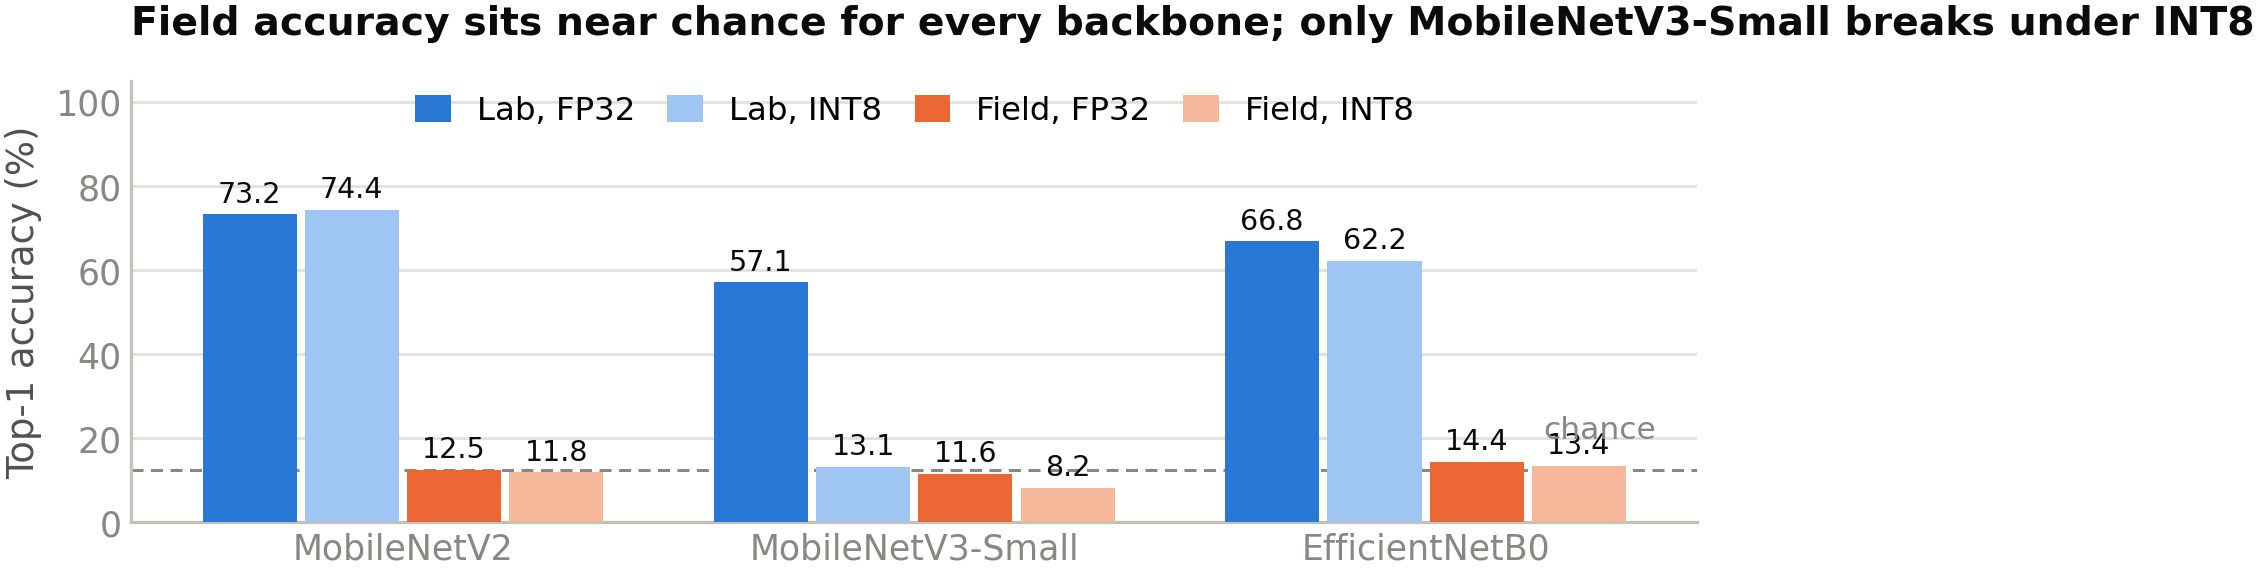

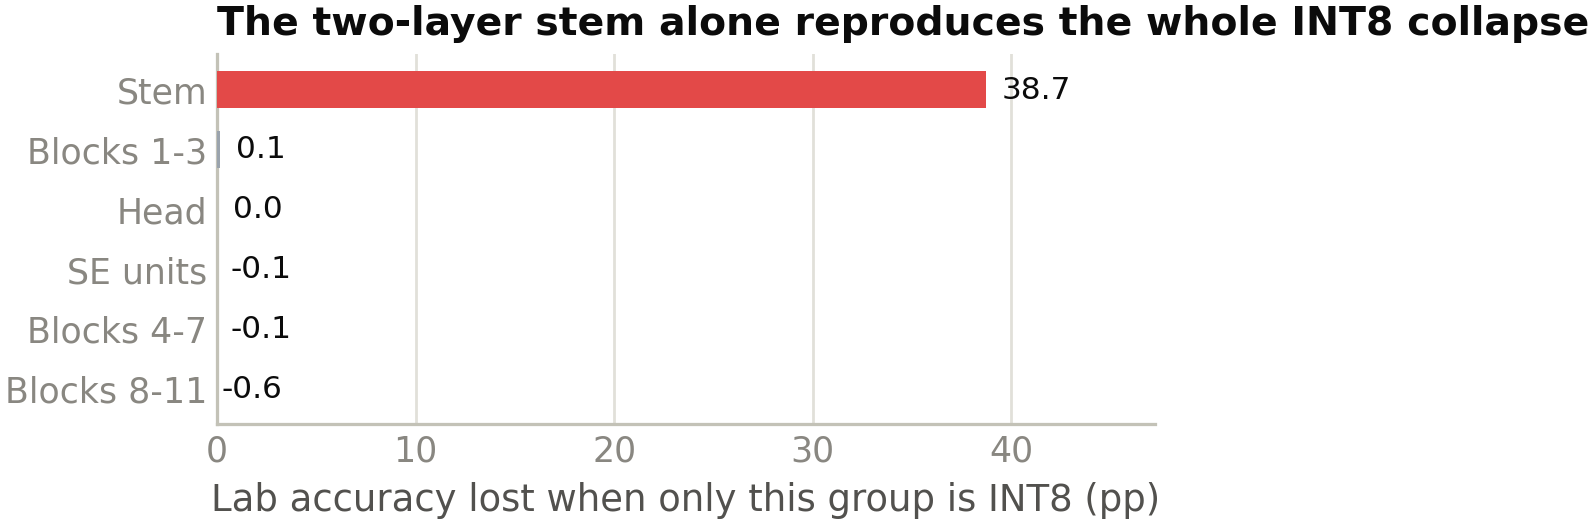

In [14]:
display(Image(filename=str(FIGURES / "multiarch_v2.png"), width=760))
display(Image(filename=str(FIGURES / "layer_sensitivity_v2.png"), width=680))

## Table 13 and Figure 15 — all eight configurations on one basis

Every saved model re-scored on $D_{\text{ft-test}}$, which is disjoint from
adaptation data for every arm. The two accountings for the stacked
configuration — against the from-scratch baseline and against the pretrained
model it was built on — are both computed here.

In [15]:
sb = load("unified_scoreboard.json")
V = {v["label"]: v for v in sb["variants"]}
order = ["From-scratch baseline", "+ full fine-tune", "+ head-only fine-tune",
         "+ L2-SP fine-tune", "+ CutMix", "ImageNet-pretrained",
         "Pretrained + head-only", "Pretrained + L2-SP"]
rows = []
for lbl in order:
    v = V[lbl]
    rows.append([lbl, 100*v["lab"], 100*v["field_fttest"],
                 100*(v["lab"] - v["field_fttest"])])
t13 = pd.DataFrame(rows, columns=["Configuration", "Laboratory %",
                                  "Field % (D_ft-test)", "gap pp"]).round(1)
display(t13)

base, pre = V["From-scratch baseline"], V["ImageNet-pretrained"]
print("\nThe two accountings for the stacked arms:")
for lbl in ["Pretrained + head-only", "Pretrained + L2-SP"]:
    v = V[lbl]
    print(f"  {lbl}")
    print(f"    vs from-scratch baseline : lab {100*(v['lab']-base['lab']):+.1f} pp, "
          f"field {100*(v['field_fttest']-base['field_fttest']):+.1f} pp")
    print(f"    vs pretrained model      : lab {100*(v['lab']-pre['lab']):+.1f} pp, "
          f"field {100*(v['field_fttest']-pre['field_fttest']):+.1f} pp")

,Configuration,Laboratory %,Field % (D_ft-test),gap pp
0,From-scratch baseline,78.7,12.2,66.6
1,+ full fine-tune,45.6,14.6,31.0
2,+ head-only fine-tune,62.9,15.6,47.3
3,+ L2-SP fine-tune,33.5,17.8,15.7
4,+ CutMix,90.5,16.3,74.3
5,ImageNet-pretrained,97.2,23.3,73.9
6,Pretrained + head-only,92.0,27.4,64.6
7,Pretrained + L2-SP,75.4,30.0,45.4



The two accountings for the stacked arms:
  Pretrained + head-only
    vs from-scratch baseline : lab +13.2 pp, field +15.2 pp
    vs pretrained model      : lab -5.2 pp, field +4.1 pp
  Pretrained + L2-SP
    vs from-scratch baseline : lab -3.3 pp, field +17.8 pp
    vs pretrained model      : lab -21.8 pp, field +6.7 pp


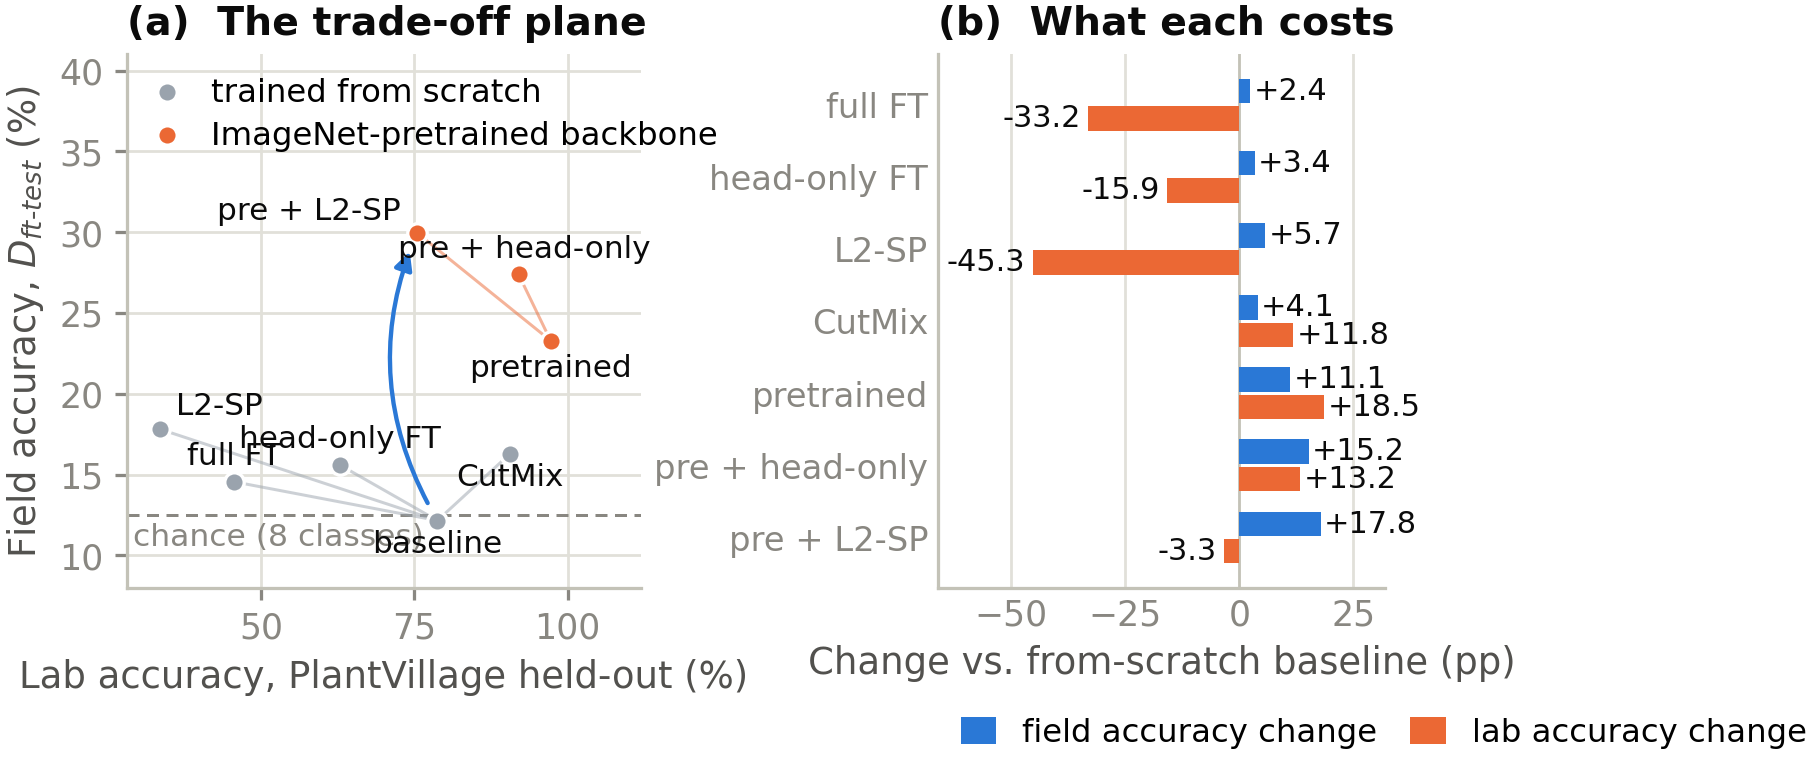

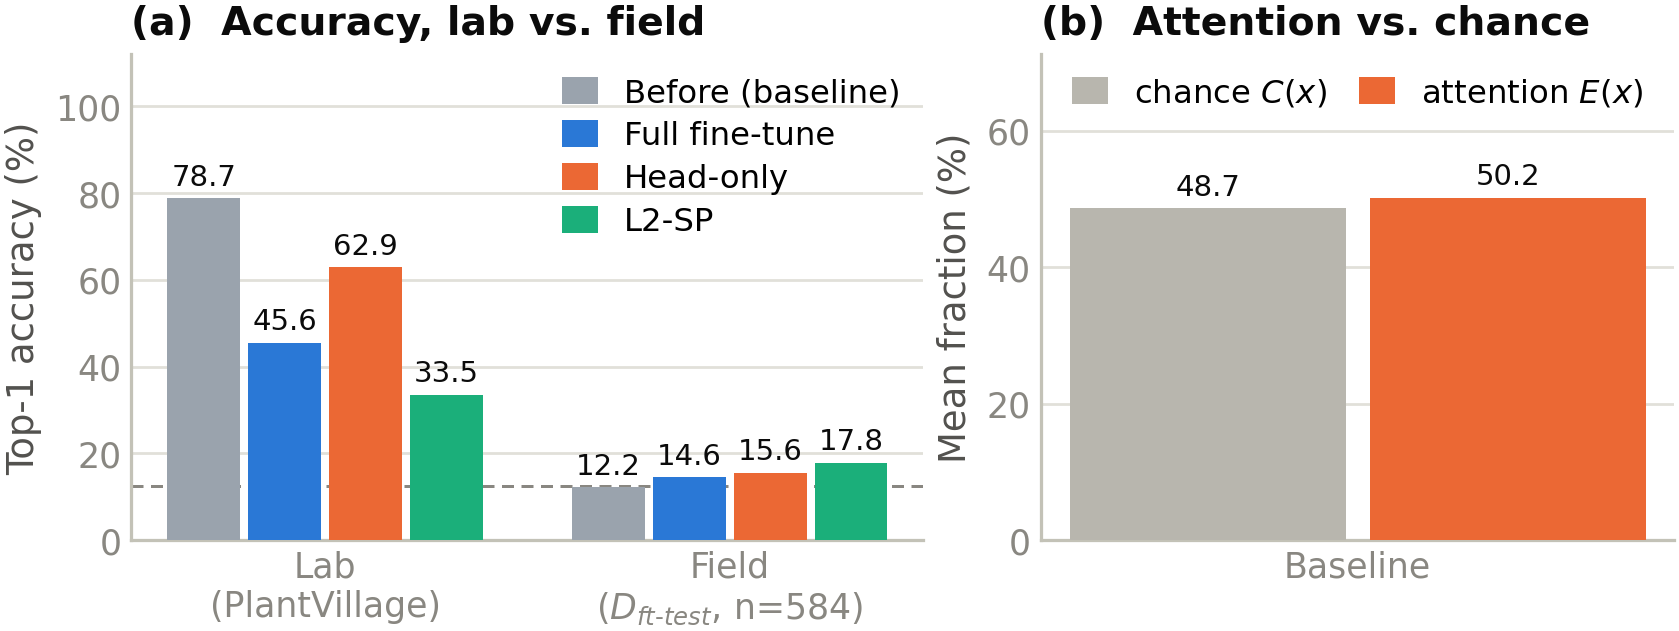

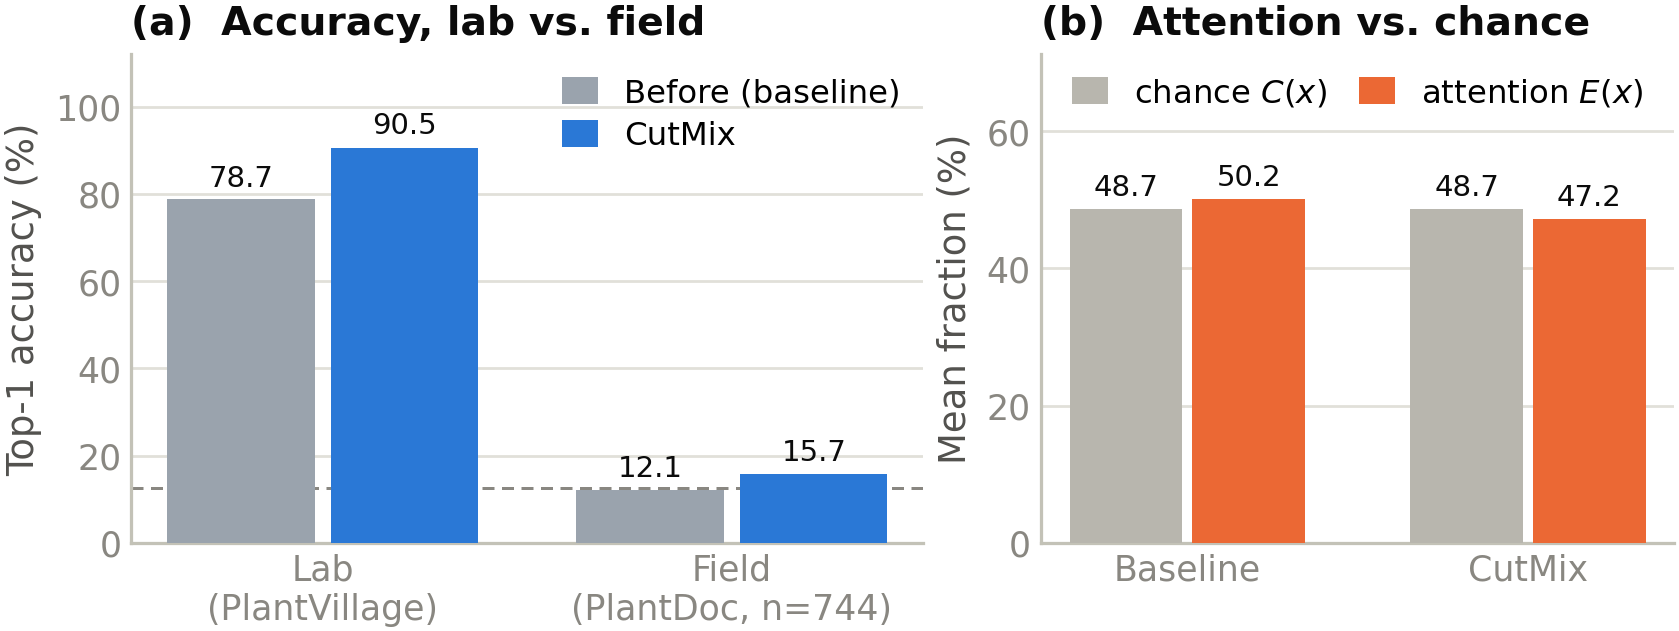

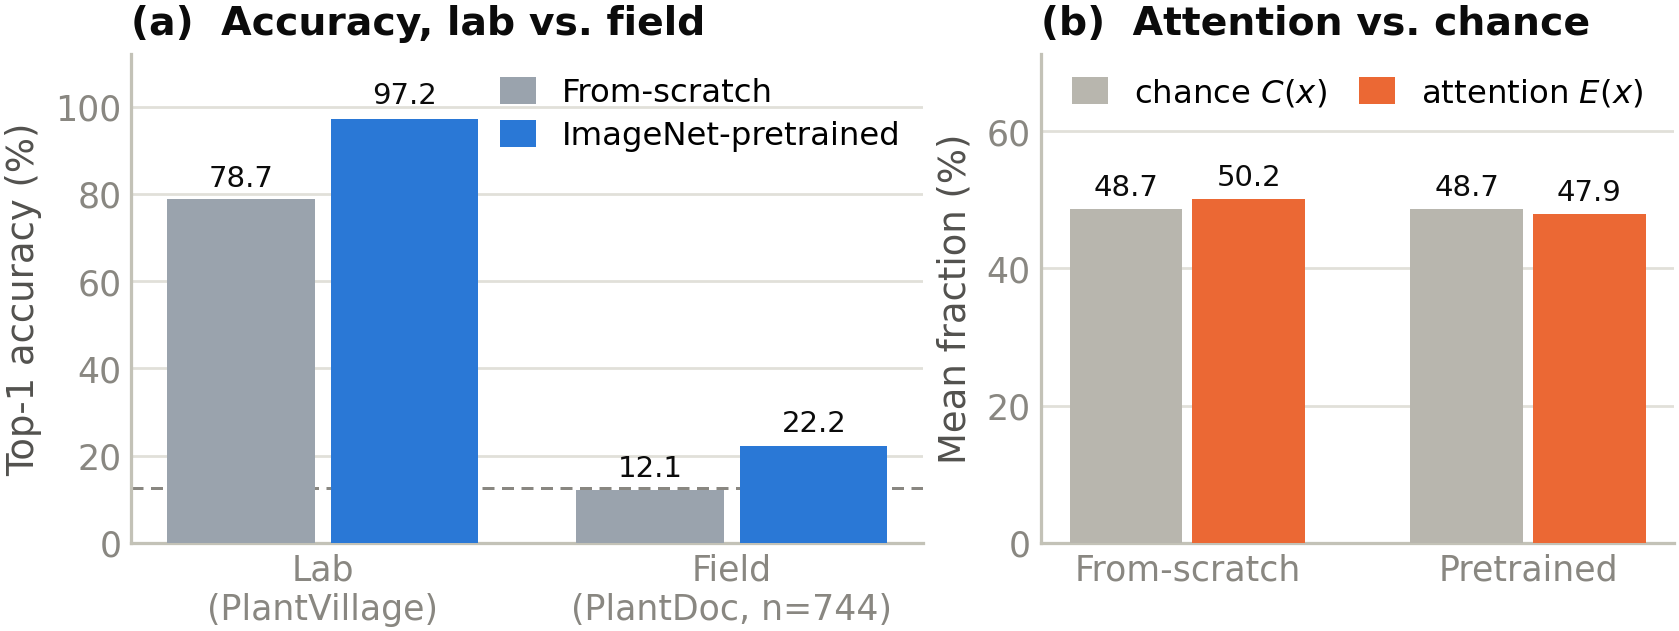

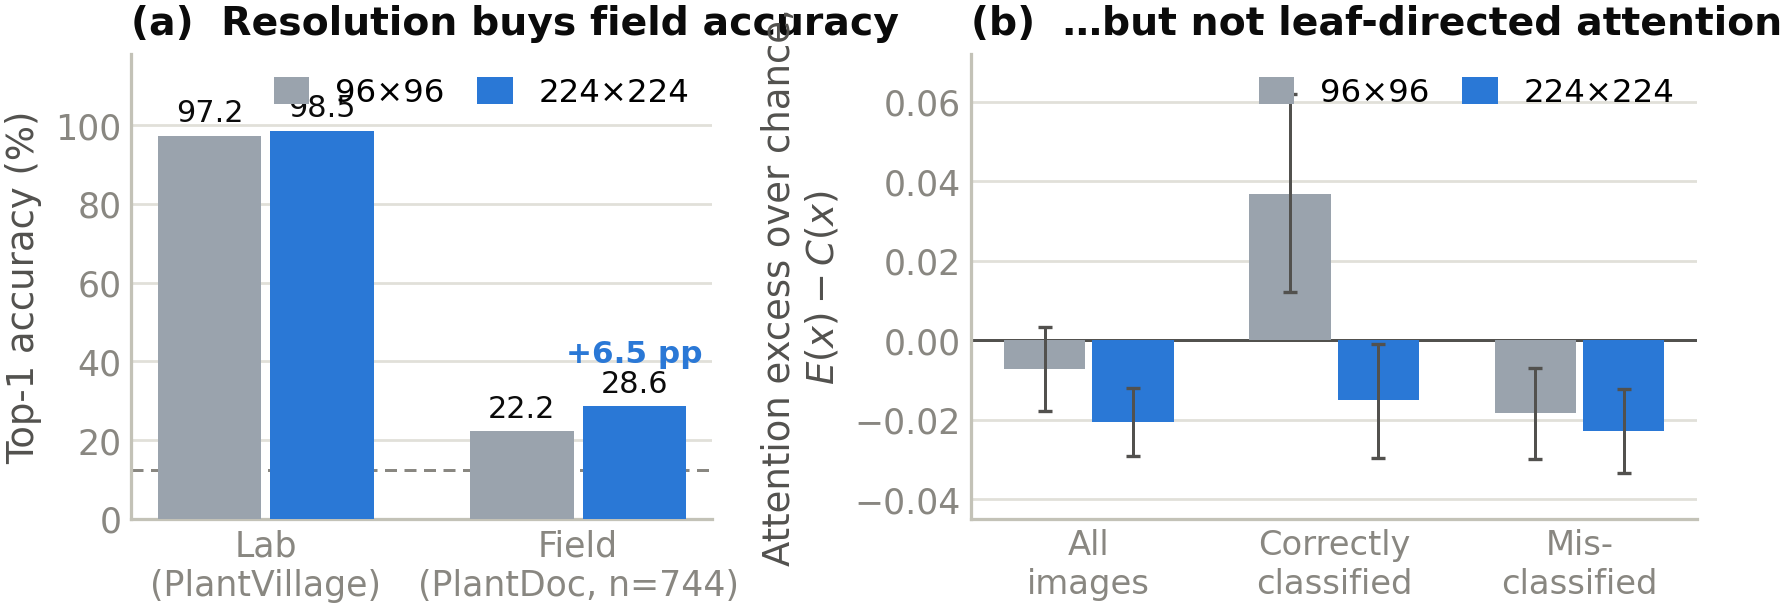

In [16]:
display(Image(filename=str(FIGURES / "tradeoff_frontier.png"), width=760))
display(Image(filename=str(FIGURES / "mitigation_v2.png"), width=760))
display(Image(filename=str(FIGURES / "cutmix_v2.png"), width=760))
display(Image(filename=str(FIGURES / "pretrained_v2.png"), width=760))
display(Image(filename=str(FIGURES / "resolution_ablation.png"), width=760))

## Table 14 — activation memory on the converted 8-bit graph

The arena is the largest total of simultaneously live activation tensors on
the TFLite graph that would actually be executed. Each peak is small enough to
check by hand, and the check is run below.

In [17]:
sram = load("peak_sram_tflite_results.json")
rows = [[v["label"].replace("$\\alpha$", "alpha"), v["n_ops"],
         v["peak_op_kb"], v["peak_arena_kb"], v["peak_arena_at"],
         "not excluded" if v["fits"]["Arduino Nano 33 BLE (nRF52840)"] else "excluded"]
        for v in sram["variants"]]
pd.DataFrame(rows, columns=["Backbone", "ops", "per-op KB", "arena KB",
                            "peak at", "256 KB part"])

,Backbone,ops,per-op KB,arena KB,peak at,256 KB part
0,MobileNetV2 (alpha=0.75),65,270.0,270.0,DEPTHWISE_CONV_2D,excluded
1,MobileNetV3-Small,108,72.0,72.0,HARD_SWISH,not excluded
2,EfficientNetB0,303,648.0,648.0,MUL,excluded
3,"MobileNetV2 (alpha=1.0, pretrained)",70,450.4,450.4,PAD,excluded


In [18]:
# Hand-check of the three peaks quoted in the paper.
checks = [
    ("MobileNetV2 alpha=0.75", 48*48*96 + 24*24*96, 270.0),
    ("MobileNetV3-Small",      48*48*16 + 48*48*16,  72.0),
    ("EfficientNetB0",         48*48*144 + 48*48*144, 648.0),
]
for name, byts, quoted in checks:
    print(f"{name:26s} {byts:8,d} B = {byts/1024:7.1f} KB   "
          f"(paper: {quoted} KB)  {'OK' if abs(byts/1024-quoted) < 0.1 else 'MISMATCH'}")

MobileNetV2 alpha=0.75      276,480 B =   270.0 KB   (paper: 270.0 KB)  OK
MobileNetV3-Small            73,728 B =    72.0 KB   (paper: 72.0 KB)  OK
EfficientNetB0              663,552 B =   648.0 KB   (paper: 648.0 KB)  OK


## Figures that appear in the paper but are not rebuilt above

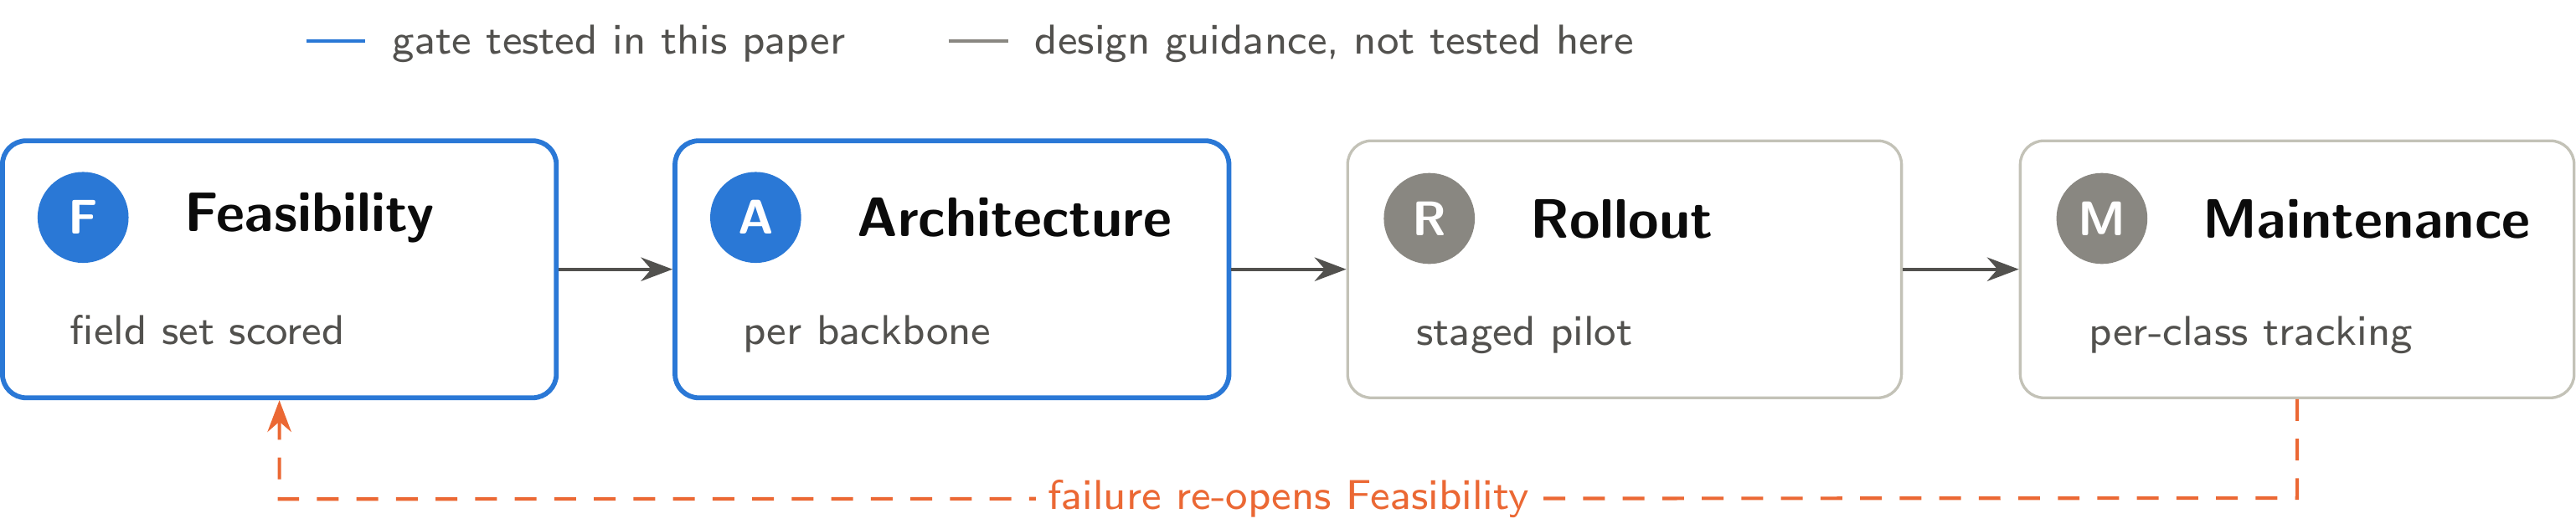

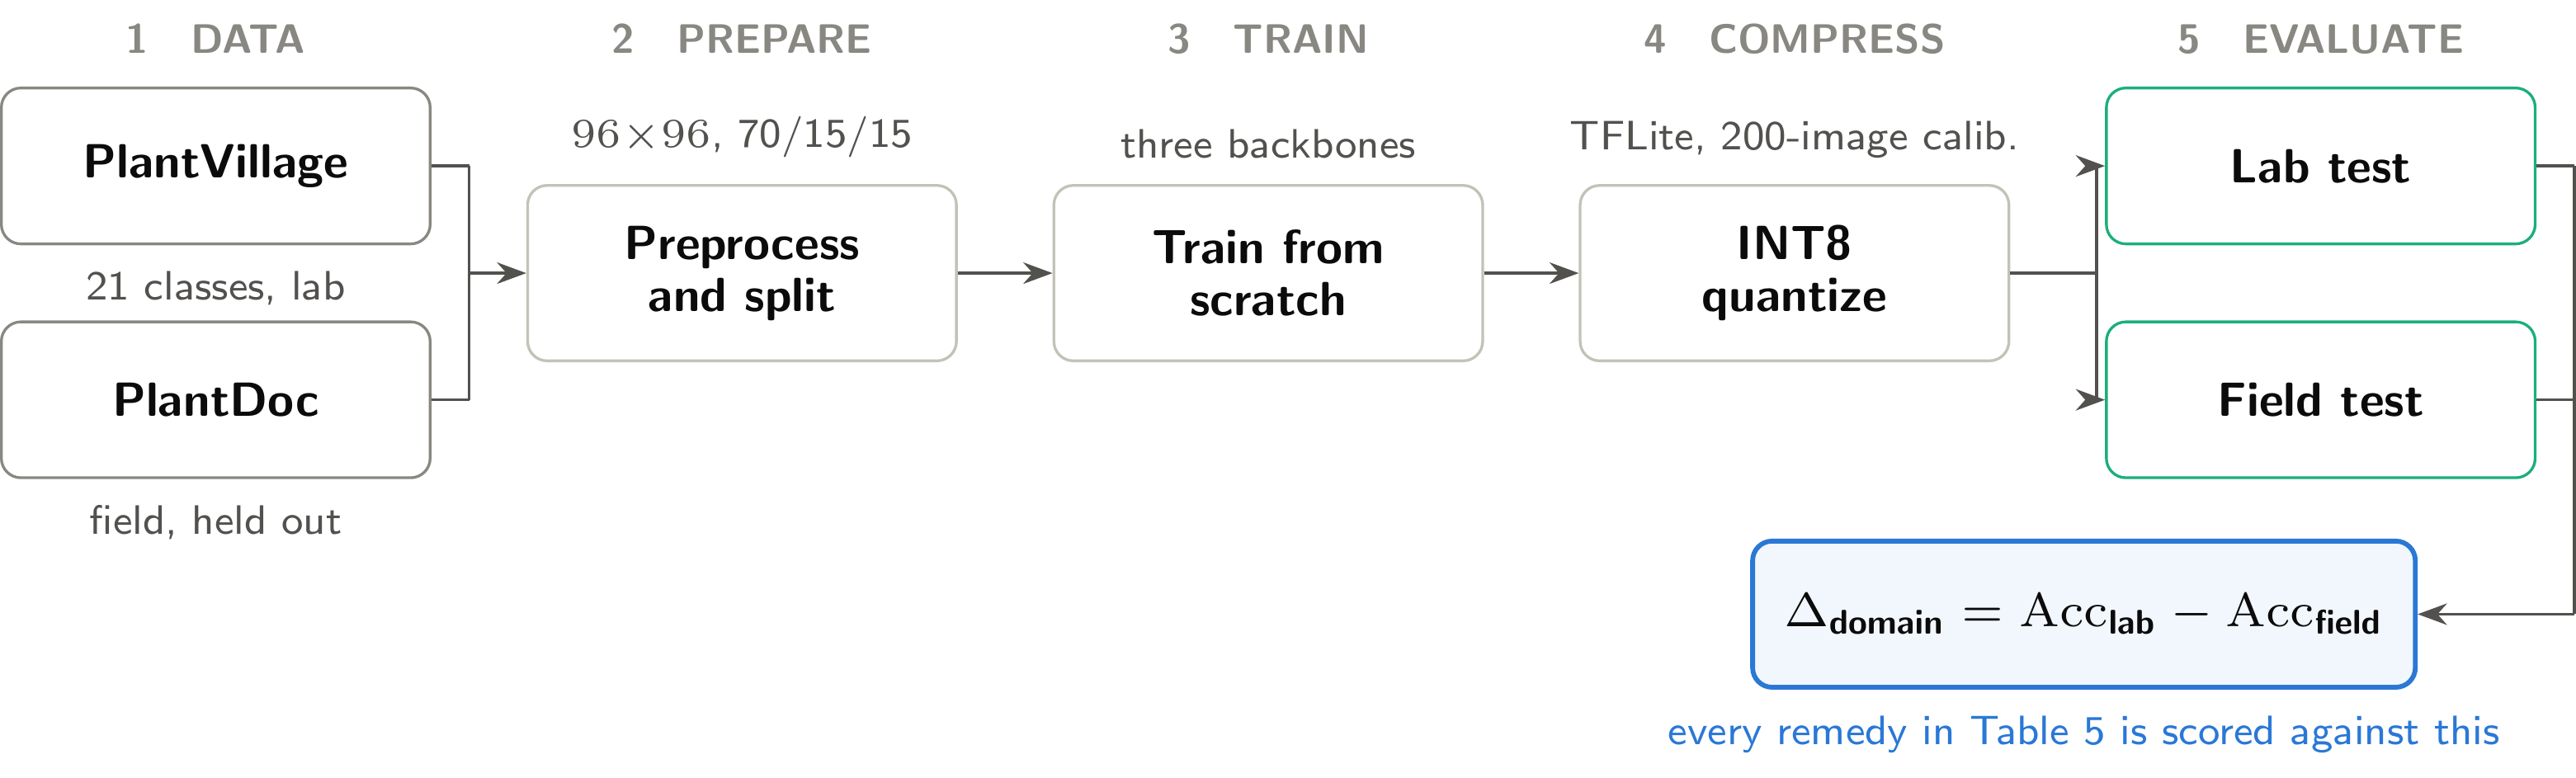

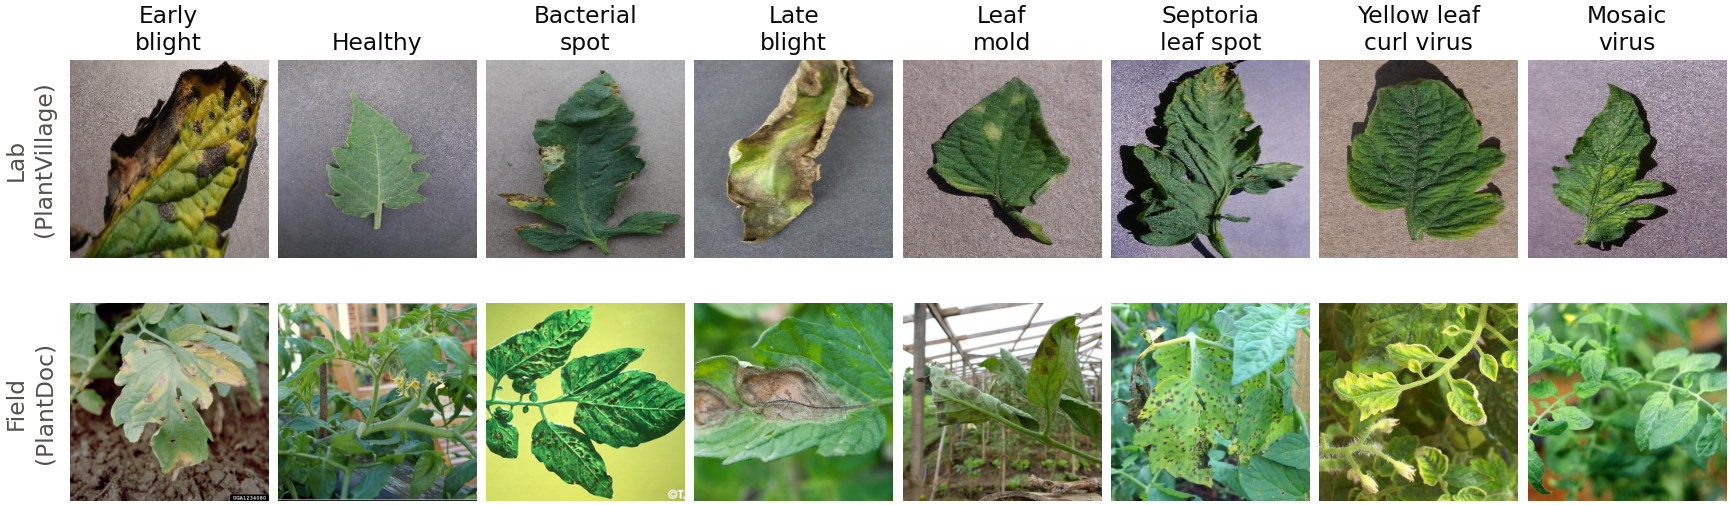

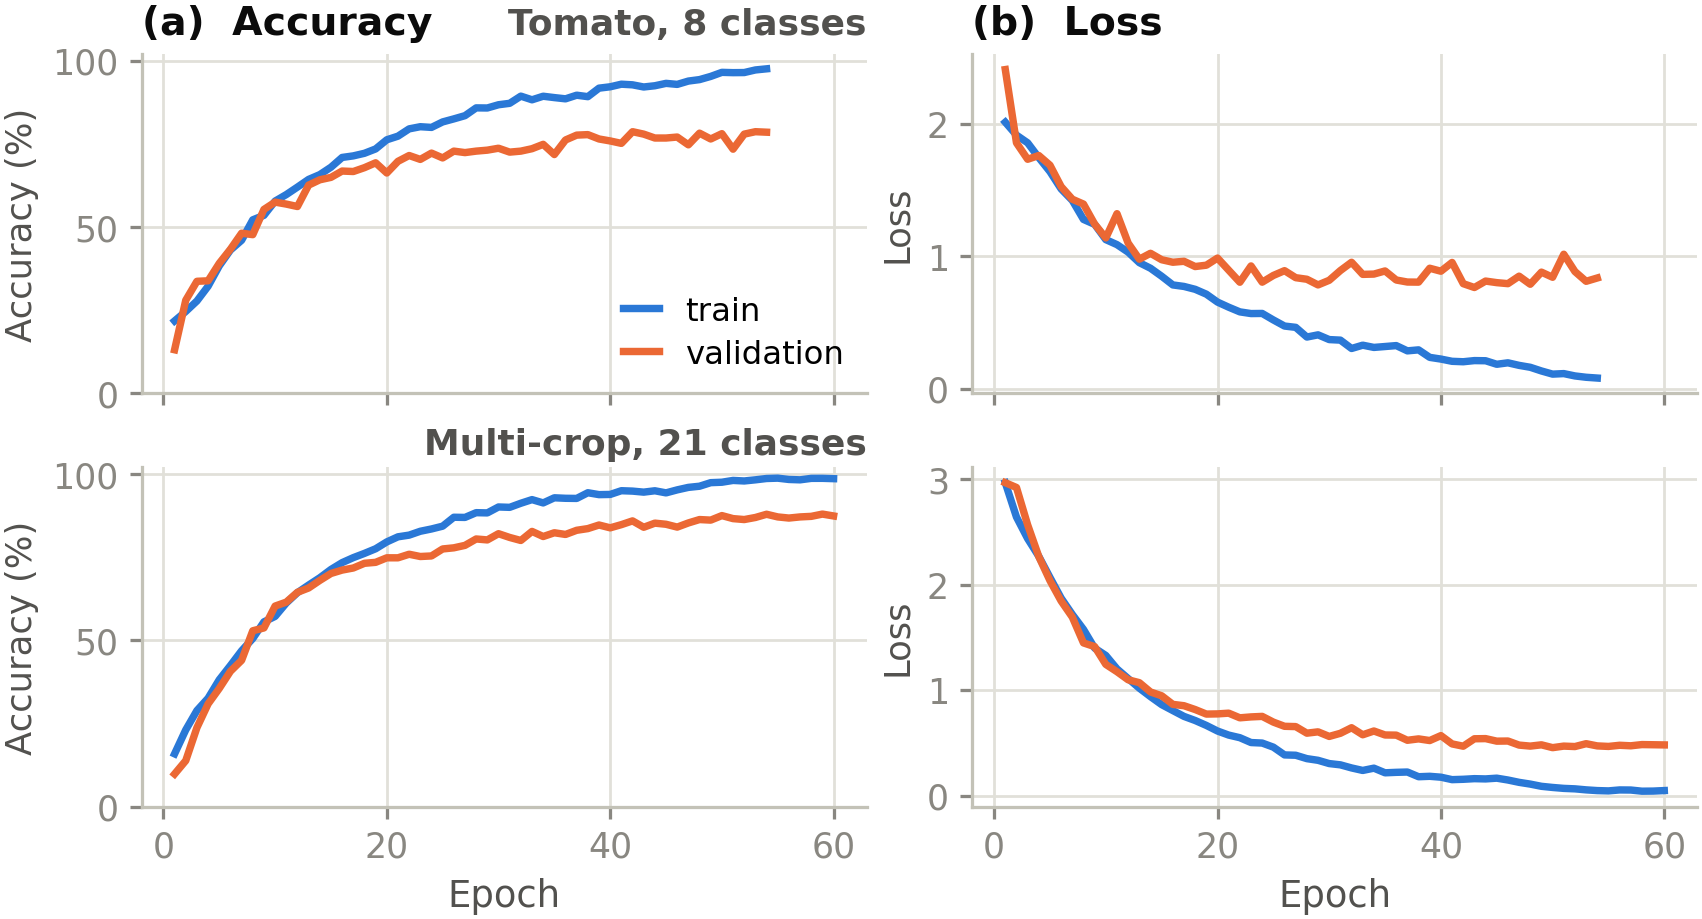

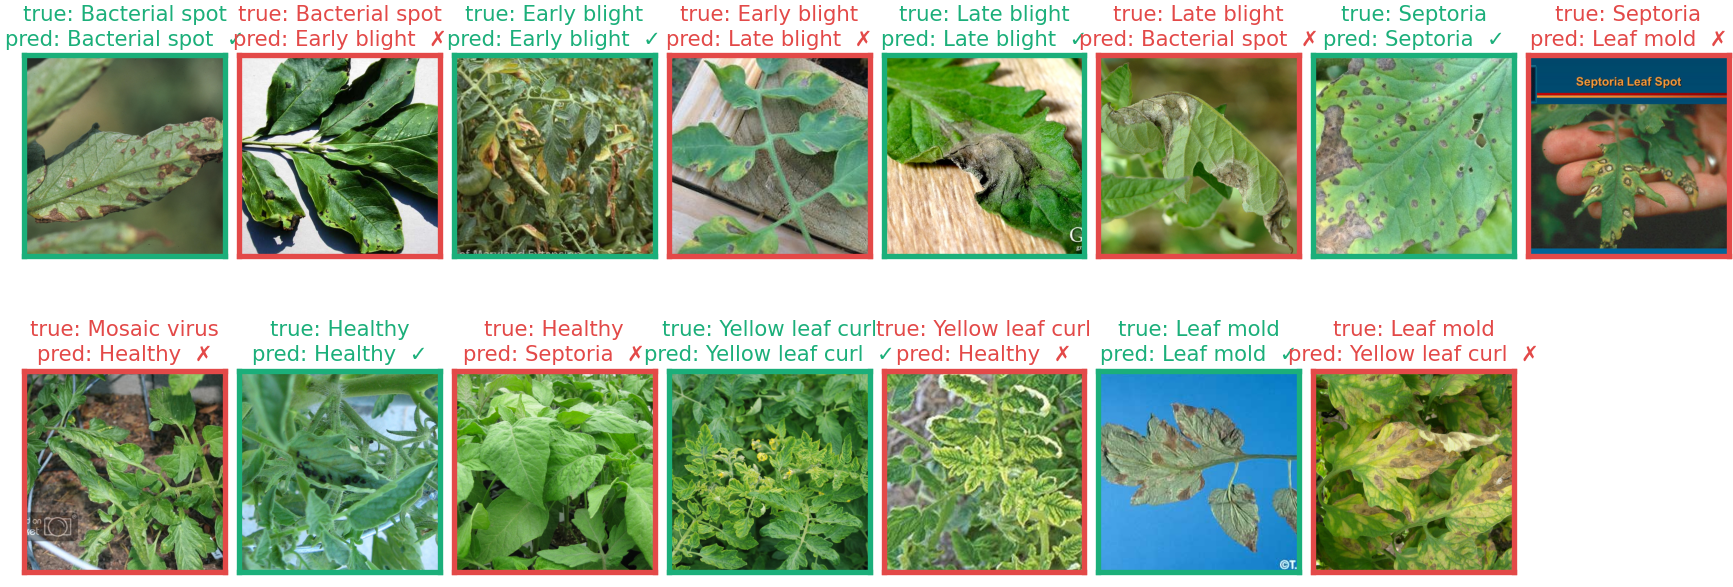

In [19]:
for f in ["fig_farm.png", "fig_pipeline.png", "lab_vs_field_samples_v3.png",
          "train_curves_v2.png", "prediction_samples_grid_v3.png"]:
    display(Image(filename=str(FIGURES / f), width=760))

---

Every number printed above is read from the saved run artefacts, not
re-derived from the manuscript. If a figure here disagrees with the paper,
the artefacts are the authority.